# Transformer from scratch

A PyTorch implementation of the encoder-decoder Transformer from *Attention Is All You Need* (Vaswani et al., 2017), built one component at a time. Everything is made from basic layers like `nn.Linear`, `nn.Embedding` and `nn.Dropout`, without using `nn.Transformer` or `nn.MultiheadAttention`.

1. Tokens
2. Token embeddings
3. Positional encoding
4. Scaled dot-product attention
5. Multi-head attention
6. Masking
7. Feed-forward network
8. Residual connections and layer norm
9. Encoder and decoder blocks
10. The full Transformer
11. Checking shapes through the model
12. Sanity checks

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

torch.manual_seed(42)
print(f"PyTorch {torch.__version__}")

PyTorch 2.14.1


In [2]:
plt.rcParams["figure.dpi"] = 110


def heatmap(ax, data, xlabels=None, ylabels=None, title=None, cmap="Blues", **kwargs):
    im = ax.imshow(data, cmap=cmap, **kwargs)
    if xlabels is not None:
        ax.set_xticks(range(len(xlabels)), xlabels, rotation=45, ha="right")
    if ylabels is not None:
        ax.set_yticks(range(len(ylabels)), ylabels)
    if title:
        ax.set_title(title)
    return im

## 1. Tokens

The model works on integer token IDs, not text. The vocabulary here is tiny: every word from three short sentences, plus four special tokens:

- `<pad>` fills shorter sequences so every row in a batch has the same length
- `<bos>` and `<eos>` mark the beginning and end of a sequence
- `<unk>` stands in for any word that isn't in the vocabulary

In [3]:
sentences = [
    "the cat sat on the mat",
    "a dog chased the ball",
    "the bird sang",
]

specials = ["<pad>", "<bos>", "<eos>", "<unk>"]
words = sorted({w for s in sentences for w in s.split()})
vocab = specials + words

stoi = {w: i for i, w in enumerate(vocab)}
itos = {i: w for w, i in stoi.items()}
PAD, BOS, EOS, UNK = (stoi[t] for t in specials)


def encode(sentence):
    return [BOS] + [stoi.get(w, UNK) for w in sentence.split()] + [EOS]


def decode(ids):
    return " ".join(itos[i] for i in ids.tolist() if i != PAD)


def pad_batch(seqs, pad_id=PAD):
    max_len = max(len(s) for s in seqs)
    return torch.tensor([s + [pad_id] * (max_len - len(s)) for s in seqs])


tokens = pad_batch([encode(s) for s in sentences])

print(f"vocab size: {len(vocab)}")
print(f"token ids:  {tuple(tokens.shape)}  (batch, seq_len)\n")
print(tokens, "\n")
for row in tokens:
    print(" ".join(f"{itos[i]:>7}" for i in row.tolist()))

vocab size: 15
token ids:  (3, 8)  (batch, seq_len)

tensor([[ 1, 14,  7, 13, 11, 14, 10,  2],
        [ 1,  4,  9,  8, 14,  5,  2,  0],
        [ 1, 14,  6, 12,  2,  0,  0,  0]]) 

  <bos>     the     cat     sat      on     the     mat   <eos>
  <bos>       a     dog  chased     the    ball   <eos>   <pad>
  <bos>     the    bird    sang   <eos>   <pad>   <pad>   <pad>


## 2. Token embeddings

An embedding layer is a lookup table: one learned vector of size `d_model` per token in the vocabulary. Indexing it with a `(batch, seq_len)` tensor of IDs returns a `(batch, seq_len, d_model)` tensor.

The paper multiplies embeddings by $\sqrt{d_{model}}$ so they sit on a similar scale to the positional encodings added in the next step.

In [4]:
class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, d_model):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.d_model = d_model

    def forward(self, tokens):
        # (batch, seq_len) -> (batch, seq_len, d_model)
        return self.embedding(tokens) * math.sqrt(self.d_model)

In [5]:
d_model = 16

token_embedding = TokenEmbedding(len(vocab), d_model)
embedded = token_embedding(tokens)

print(f"token ids:  {tuple(tokens.shape)}")
print(f"embeddings: {tuple(embedded.shape)}  (batch, seq_len, d_model)")

token ids:  (3, 8)
embeddings: (3, 8, 16)  (batch, seq_len, d_model)


## 3. Positional encoding

Attention on its own has no sense of order: shuffle the input tokens and you get the same outputs, just shuffled. To fix that, a fixed vector that depends only on position is added to each embedding:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right) \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

Each pair of dimensions is a sine/cosine wave at a different frequency. Early dimensions oscillate quickly and later ones slowly, so every position gets a unique pattern and nearby positions get similar ones.

In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

        position = torch.arange(max_len).unsqueeze(1)                                         # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))  # (d_model / 2,)

        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        # A buffer moves with the model (.to(device), state_dict) but isn't a trainable parameter
        self.register_buffer("pe", pe.unsqueeze(0))  # (1, max_len, d_model)

    def forward(self, x):
        # (batch, seq_len, d_model) -> (batch, seq_len, d_model)
        x = x + self.pe[:, : x.size(1)]
        return self.dropout(x)

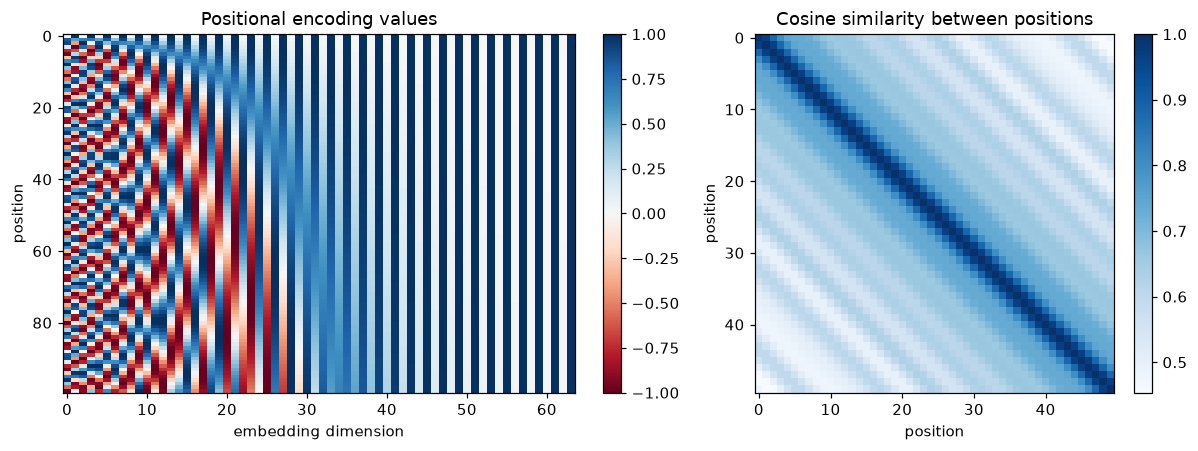

In [7]:
pe = PositionalEncoding(d_model=64, max_len=100, dropout=0.0).pe[0]  # (100, 64)
unit = F.normalize(pe[:50], dim=-1)
similarity = unit @ unit.T                                           # cosine similarity between positions

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})

im1 = heatmap(ax1, pe, cmap="RdBu", vmin=-1, vmax=1, aspect="auto", title="Positional encoding values")
ax1.set_xlabel("embedding dimension")
ax1.set_ylabel("position")
fig.colorbar(im1, ax=ax1, fraction=0.04)

im2 = heatmap(ax2, similarity, title="Cosine similarity between positions")
ax2.set_xlabel("position")
ax2.set_ylabel("position")
fig.colorbar(im2, ax=ax2, fraction=0.046)

plt.tight_layout()
plt.show()

The left plot shows the fast waves in the first dimensions and the slow ones further right. On the right, each position is most similar to itself and its neighbors, and similarity falls off with distance.

Adding the encoding means the same word at two different positions now gets two different vectors. "the" appears at positions 1 and 5 in the first sentence:

In [8]:
positional_encoding = PositionalEncoding(d_model, dropout=0.0)
x = positional_encoding(embedded)

p1, p2 = (tokens[0] == stoi["the"]).nonzero().flatten().tolist()
print(f'"the" at positions {p1} and {p2}')
print(f"same vector before positional encoding: {torch.allclose(embedded[0, p1], embedded[0, p2])}")
print(f"same vector after positional encoding:  {torch.allclose(x[0, p1], x[0, p2])}")
print(f"\nshape after adding positions: {tuple(x.shape)}")

"the" at positions 1 and 5
same vector before positional encoding: True
same vector after positional encoding:  False

shape after adding positions: (3, 8, 16)


## 4. Scaled dot-product attention

Attention lets each token pull information from the other tokens in the sequence. Every token is projected into three vectors:

- query: what this token is looking for
- key: what this token offers for matching
- value: the information it passes on when another token attends to it

The score between two tokens is the dot product of one's query with the other's key, divided by $\sqrt{d_k}$ so the scores don't grow with dimension and saturate the softmax. Softmax turns each row of scores into weights that sum to 1, and each token's output is the weighted sum of the values:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

The function below also takes an optional boolean mask (`True` = allowed to attend). Blocked positions get a huge negative score before the softmax, so their weight comes out as 0. The masks themselves get built in section 6.

In [9]:
def scaled_dot_product_attention(q, k, v, mask=None, dropout=None):
    # q: (..., seq_q, d_k)   k: (..., seq_k, d_k)   v: (..., seq_k, d_v)
    # mask: broadcastable to (..., seq_q, seq_k), True where attention is allowed
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)  # (..., seq_q, seq_k)

    if mask is not None:
        # Most negative finite float rather than -inf, so a fully masked row can't produce NaNs
        scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)

    weights = scores.softmax(dim=-1)
    attn = dropout(weights) if dropout is not None else weights
    return attn @ v, weights  # (..., seq_q, d_v), (..., seq_q, seq_k)

Try it on the first sentence. Three linear layers turn the position-aware embeddings into queries, keys and values.

In [10]:
w_q = nn.Linear(d_model, d_model)
w_k = nn.Linear(d_model, d_model)
w_v = nn.Linear(d_model, d_model)

with torch.no_grad():
    x0 = x[0]                       # first sentence: (seq_len, d_model)
    q, k, v = w_q(x0), w_k(x0), w_v(x0)
    out, weights = scaled_dot_product_attention(q, k, v)

print(f"queries, keys, values: {tuple(q.shape)}")
print(f"attention weights:     {tuple(weights.shape)}  (query, key)")
print(f"output:                {tuple(out.shape)}")
print(f"row sums:              {weights.sum(-1)}")

queries, keys, values: (8, 16)
attention weights:     (8, 8)  (query, key)
output:                (8, 16)
row sums:              tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


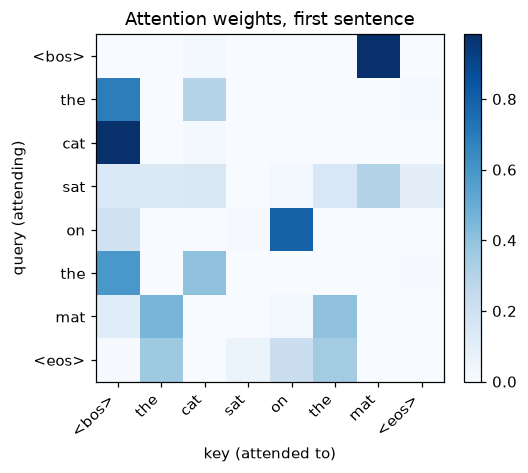

In [11]:
labels = [itos[i] for i in tokens[0].tolist()]

fig, ax = plt.subplots(figsize=(5, 4.4))
im = heatmap(ax, weights, xlabels=labels, ylabels=labels, vmin=0,
             title="Attention weights, first sentence")
ax.set_xlabel("key (attended to)")
ax.set_ylabel("query (attending)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

The weights are random since nothing is trained yet. Row *i* is how much token *i* pulls from each token in the sequence, and every row sums to 1.

## 5. Multi-head attention

A single attention operation gives each token one weighted mix of the others. Multi-head attention runs `num_heads` of them in parallel. Each head has its own query, key and value projections into a smaller space of size `d_head = d_model / num_heads`, so each one can pick up a different kind of relationship. The head outputs are concatenated and mixed by a final linear layer $W^O$:

$$\text{MultiHead}(Q,K,V) = \text{Concat}(\text{head}_1,\dots,\text{head}_h)\,W^O \qquad \text{head}_i = \text{Attention}(QW_i^Q,\ KW_i^K,\ VW_i^V)$$

Instead of keeping `h` separate small linear layers, one `d_model × d_model` layer computes every head's projection at once, and the result is reshaped so heads get their own dimension. It's the same math done in one matrix multiply.

In [12]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_head = d_model // num_heads

        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

        self.attn_weights = None  # weights from the last forward pass, kept for inspection

    def split_heads(self, x):
        # (batch, seq_len, d_model) -> (batch, num_heads, seq_len, d_head)
        batch, seq_len, _ = x.shape
        return x.view(batch, seq_len, self.num_heads, self.d_head).transpose(1, 2)

    def combine_heads(self, x):
        # (batch, num_heads, seq_len, d_head) -> (batch, seq_len, d_model)
        batch, _, seq_len, _ = x.shape
        return x.transpose(1, 2).contiguous().view(batch, seq_len, self.d_model)

    def forward(self, query, key, value, mask=None):
        q = self.split_heads(self.w_q(query))
        k = self.split_heads(self.w_k(key))
        v = self.split_heads(self.w_v(value))

        out, weights = scaled_dot_product_attention(q, k, v, mask, self.dropout)
        self.attn_weights = weights.detach()

        return self.w_o(self.combine_heads(out))

Check that each head really has its own weights: head *h*'s queries should come from its own block of rows in `w_q`, exactly as if it were a separate `d_model → d_head` linear layer.

In [13]:
num_heads = 4
mha = MultiHeadAttention(d_model, num_heads, dropout=0.0)
d_head = mha.d_head

with torch.no_grad():
    q_heads = mha.split_heads(mha.w_q(x))  # (batch, heads, seq_len, d_head)
    for h in range(num_heads):
        rows = slice(h * d_head, (h + 1) * d_head)
        q_h = x @ mha.w_q.weight[rows].T + mha.w_q.bias[rows]
        print(f"head {h}: uses rows {rows.start:>2}-{rows.stop - 1:>2} of W_q -> matches: "
              f"{torch.allclose(q_heads[:, h], q_h, atol=1e-6)}")

head 0: uses rows  0- 3 of W_q -> matches: True
head 1: uses rows  4- 7 of W_q -> matches: True
head 2: uses rows  8-11 of W_q -> matches: True
head 3: uses rows 12-15 of W_q -> matches: True


Now run it on the whole batch. In self-attention the query, key and value inputs are all the same sequence.

In [14]:
with torch.no_grad():
    out = mha(x, x, x)

print(f"input:             {tuple(x.shape)}")
print(f"queries per head:  {tuple(q_heads.shape)}  (batch, heads, seq_len, d_head)")
print(f"attention weights: {tuple(mha.attn_weights.shape)}  (batch, heads, query, key)")
print(f"output:            {tuple(out.shape)}")

input:             (3, 8, 16)
queries per head:  (3, 4, 8, 4)  (batch, heads, seq_len, d_head)
attention weights: (3, 4, 8, 8)  (batch, heads, query, key)
output:            (3, 8, 16)


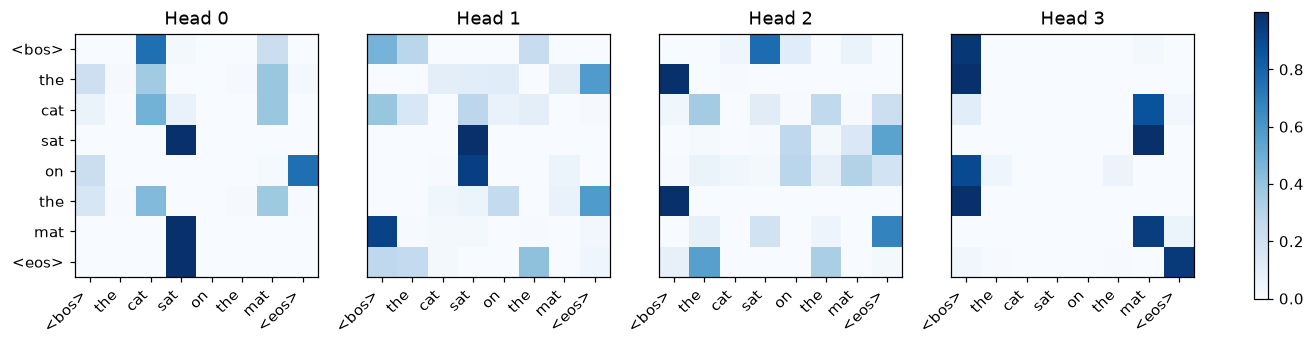

In [15]:
fig, axes = plt.subplots(1, num_heads, figsize=(14, 3.8))
vmax = mha.attn_weights[0].max().item()
for h, ax in enumerate(axes):
    im = heatmap(ax, mha.attn_weights[0, h], xlabels=labels, ylabels=labels if h == 0 else [],
                 vmin=0, vmax=vmax, title=f"Head {h}")
fig.colorbar(im, ax=axes, fraction=0.012)
plt.show()

Each head starts from its own random weights, so the same sentence gives four different patterns. None of them mean anything until the model is trained.

## 6. Masking

Two kinds of mask:

**Padding mask.** Shorter sentences are filled out with `<pad>` tokens. They carry no meaning, so no token should attend to them. The mask has shape `(batch, 1, 1, seq_len)` and broadcasts across every head and every query position.

**Causal (look-ahead) mask.** During training the decoder gets the whole target sentence at once, but when predicting token *i* it may only use tokens before it. A lower-triangular mask blocks everything above the diagonal. The decoder combines this with its padding mask.

In [16]:
def make_padding_mask(tokens, pad_id=PAD):
    # (batch, seq_len) -> (batch, 1, 1, seq_len), True where the key is a real token
    return (tokens != pad_id).unsqueeze(1).unsqueeze(2)


def make_causal_mask(seq_len, device=None):
    # (1, 1, seq_len, seq_len), True where key position <= query position
    mask = torch.tril(torch.ones(seq_len, seq_len, dtype=torch.bool, device=device))
    return mask.view(1, 1, seq_len, seq_len)


def make_decoder_mask(tokens, pad_id=PAD):
    # (batch, 1, seq_len, seq_len): padding and causal combined
    return make_padding_mask(tokens, pad_id) & make_causal_mask(tokens.size(1), tokens.device)


pad_mask = make_padding_mask(tokens)
causal_mask = make_causal_mask(tokens.size(1))
dec_mask = make_decoder_mask(tokens)

print(f"padding mask: {tuple(pad_mask.shape)}")
print(f"causal mask:  {tuple(causal_mask.shape)}")
print(f"decoder mask: {tuple(dec_mask.shape)}")

padding mask: (3, 1, 1, 8)
causal mask:  (1, 1, 8, 8)
decoder mask: (3, 1, 8, 8)


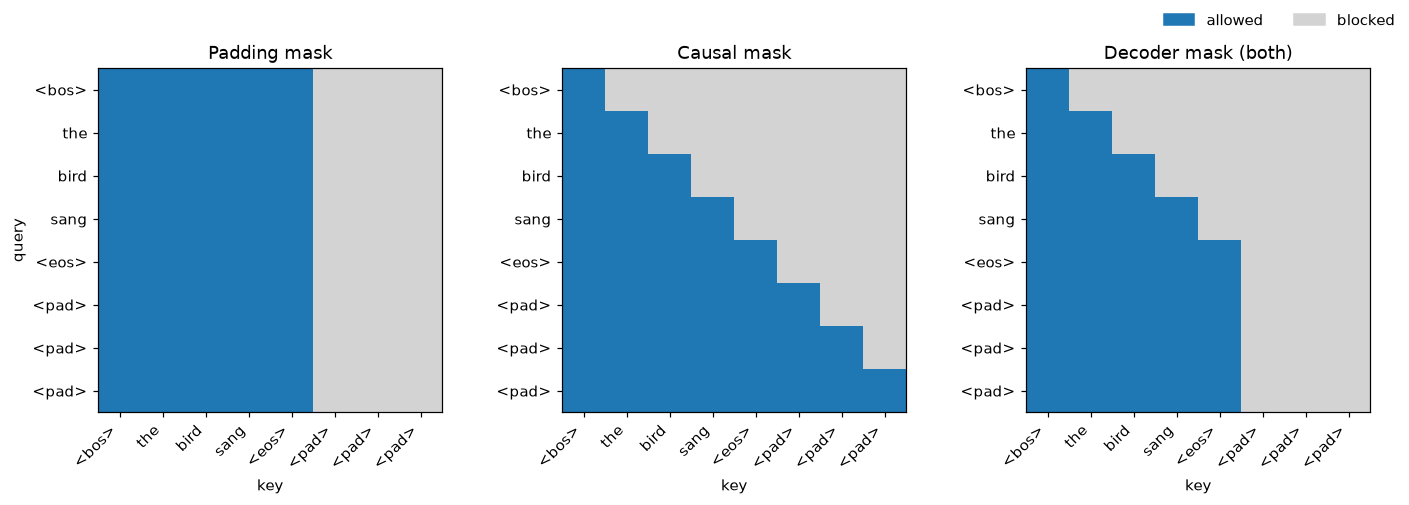

In [17]:
i = 2  # third sentence, which has padding
seq_len = tokens.size(1)
labels3 = [itos[t] for t in tokens[i].tolist()]

mask_cmap = ListedColormap(["lightgray", "tab:blue"])  # blocked, allowed

panels = [
    ("Padding mask", pad_mask[i, 0].expand(seq_len, seq_len)),
    ("Causal mask", causal_mask[0, 0]),
    ("Decoder mask (both)", dec_mask[i, 0]),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, (title, mask) in zip(axes, panels):
    heatmap(ax, mask.int(), xlabels=labels3, ylabels=labels3, cmap=mask_cmap, vmin=0, vmax=1, title=title)
    ax.set_xlabel("key")
axes[0].set_ylabel("query")
fig.legend(handles=[Patch(color="tab:blue", label="allowed"), Patch(color="lightgray", label="blocked")],
           loc="upper right", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

Apply the decoder mask to multi-head attention on the third sentence and confirm that blocked positions get exactly zero weight.

max weight on padding keys:     0.0
max weight above the diagonal:  0.0
rows still sum to 1:            True


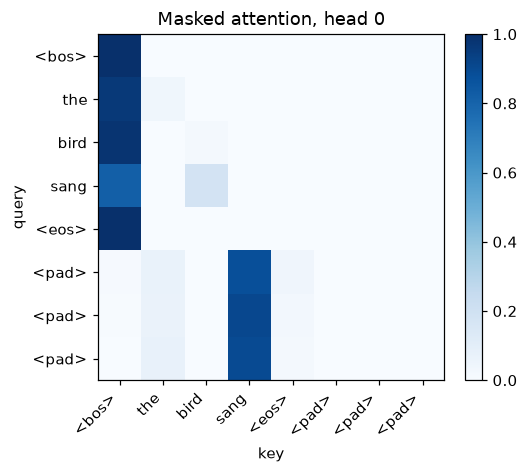

In [18]:
with torch.no_grad():
    mha(x, x, x, mask=dec_mask)

w = mha.attn_weights[i, 0]  # third sentence, head 0
print(f"max weight on padding keys:     {w[:, tokens[i] == PAD].max().item()}")
print(f"max weight above the diagonal:  {torch.triu(w, diagonal=1).max().item()}")
print(f"rows still sum to 1:            {torch.allclose(w.sum(-1), torch.ones(seq_len))}")

fig, ax = plt.subplots(figsize=(5, 4.4))
im = heatmap(ax, w, xlabels=labels3, ylabels=labels3, vmin=0, title="Masked attention, head 0")
ax.set_xlabel("key")
ax.set_ylabel("query")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 7. Position-wise feed-forward network

Attention moves information between tokens. The feed-forward network then processes each token's updated vector on its own: two linear layers with a ReLU in between, applied identically at every position.

$$\text{FFN}(x) = \max(0,\ xW_1 + b_1)\,W_2 + b_2$$

The hidden layer `d_ff` is wider than the model, 4 × `d_model` in the paper.

In [19]:
class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )

    def forward(self, x):
        # (batch, seq_len, d_model) -> (batch, seq_len, d_model)
        return self.net(x)

In [20]:
ffn = PositionwiseFeedForward(d_model, d_ff=4 * d_model, dropout=0.0)

with torch.no_grad():
    y = ffn(x)
    single = ffn(x[0, 3])  # one token processed on its own

print(f"input:  {tuple(x.shape)}")
print(f"hidden: {tuple(ffn.net[0](x).shape)}  (d_ff = {4 * d_model})")
print(f"output: {tuple(y.shape)}")
print(f"\nsame result when a token is processed alone: {torch.allclose(y[0, 3], single, atol=1e-6)}")

input:  (3, 8, 16)
hidden: (3, 8, 64)  (d_ff = 64)
output: (3, 8, 16)

same result when a token is processed alone: True


## 8. Residual connections and layer normalization

Every sub-layer (attention or feed-forward) gets wrapped the same way:

$$\text{output} = \text{LayerNorm}\big(x + \text{Sublayer}(x)\big)$$

The **residual (skip) connection** adds the input back onto the sub-layer's output. Each sub-layer only has to learn a change to its input, and gradients get a direct path back through the stack.

**Layer normalization** rescales each token's vector to zero mean and unit variance across its features, then applies a learned scale $\gamma$ and shift $\beta$. This keeps activations in a stable range as layers stack up.

This is the post-norm arrangement from the original paper. Many later models move the norm in front of the sub-layer ("pre-norm"), which tends to be more stable in very deep stacks.

In [21]:
class LayerNorm(nn.Module):
    def __init__(self, d_model, eps=1e-5):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x):
        # Normalize over the feature dimension, separately for every token
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        return self.gamma * (x - mean) / torch.sqrt(var + self.eps) + self.beta


class ResidualLayerNorm(nn.Module):
    # LayerNorm(x + Dropout(sublayer(x)))
    def __init__(self, d_model, dropout=0.1):
        super().__init__()
        self.norm = LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, sublayer):
        return self.norm(x + self.dropout(sublayer(x)))

In [22]:
raw = torch.randn(2, 5, d_model) * 4 + 3  # deliberately off-center and spread out
ln = LayerNorm(d_model)

with torch.no_grad():
    normed = ln(raw)

print(f"{'token':<8}{'mean before':>12}{'std before':>12}{'mean after':>12}{'std after':>12}")
for t in range(4):
    before, after = raw[0, t], normed[0, t]
    stats = [before.mean(), before.std(unbiased=False), after.mean(), after.std(unbiased=False)]
    print(f"{t:<8}" + "".join(f"{round(v.item(), 3) + 0.0:>12.3f}" for v in stats))
print(f"\nmatches nn.LayerNorm: {torch.allclose(normed, nn.LayerNorm(d_model)(raw), atol=1e-5)}")

token    mean before  std before  mean after   std after
0              2.275       4.063       0.000       1.000
1              2.047       3.570       0.000       1.000
2              3.493       3.600       0.000       1.000
3              3.205       4.617       0.000       1.000

matches nn.LayerNorm: True


## 9. Encoder and decoder blocks

An encoder layer is self-attention over the source sentence followed by the feed-forward network, each wrapped in residual + layer norm.

A decoder layer has three sub-layers, wrapped the same way:

1. Masked self-attention over the target sequence so far (padding + causal mask)
2. Cross-attention, where the queries come from the decoder and the keys and values come from the encoder output (the "memory"). This is how the decoder reads the source sentence.
3. The feed-forward network

The encoder and decoder are each a stack of `num_layers` of these.

In [23]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.residual1 = ResidualLayerNorm(d_model, dropout)
        self.residual2 = ResidualLayerNorm(d_model, dropout)

    def forward(self, x, src_mask):
        x = self.residual1(x, lambda x: self.self_attn(x, x, x, src_mask))
        x = self.residual2(x, self.feed_forward)
        return x


class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.residual1 = ResidualLayerNorm(d_model, dropout)
        self.residual2 = ResidualLayerNorm(d_model, dropout)
        self.residual3 = ResidualLayerNorm(d_model, dropout)

    def forward(self, x, memory, src_mask, tgt_mask):
        x = self.residual1(x, lambda x: self.self_attn(x, x, x, tgt_mask))
        x = self.residual2(x, lambda x: self.cross_attn(x, memory, memory, src_mask))
        x = self.residual3(x, self.feed_forward)
        return x


class Encoder(nn.Module):
    def __init__(self, num_layers, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList(
            [EncoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)]
        )

    def forward(self, x, src_mask):
        for layer in self.layers:
            x = layer(x, src_mask)
        return x


class Decoder(nn.Module):
    def __init__(self, num_layers, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList(
            [DecoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)]
        )

    def forward(self, x, memory, src_mask, tgt_mask):
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return x

In [24]:
enc_layer = EncoderLayer(d_model, num_heads, d_ff=4 * d_model, dropout=0.0)
dec_layer = DecoderLayer(d_model, num_heads, d_ff=4 * d_model, dropout=0.0)

src_x = x                 # stands in for an embedded source sentence
tgt_x = x[:, :6]          # a shorter target sequence, to show the two lengths stay separate
src_mask = make_padding_mask(tokens)
tgt_mask = make_decoder_mask(tokens[:, :6])

with torch.no_grad():
    memory = enc_layer(src_x, src_mask)
    dec_out = dec_layer(tgt_x, memory, src_mask, tgt_mask)

print(f"encoder layer: {tuple(src_x.shape)} -> {tuple(memory.shape)}")
print(f"decoder layer: {tuple(tgt_x.shape)} + memory {tuple(memory.shape)} -> {tuple(dec_out.shape)}")
print(f"cross-attention weights: {tuple(dec_layer.cross_attn.attn_weights.shape)}  (batch, heads, target, source)")

encoder layer: (3, 8, 16) -> (3, 8, 16)
decoder layer: (3, 6, 16) + memory (3, 8, 16) -> (3, 6, 16)
cross-attention weights: (3, 4, 6, 8)  (batch, heads, target, source)


## 10. The full Transformer

```
source tokens ─► embedding ─► + position ─► encoder layer × N ──────────► memory
                                                                             │
target tokens ─► embedding ─► + position ─► decoder layer × N ◄──────────────┘
                                                   │
                                                   └─► linear ─► logits over the vocabulary
```

The decoder input is the target sequence shifted right (it starts with `<bos>`), and at each position the model outputs a score for every word in the vocabulary as the next token. Weight matrices are initialized with Xavier uniform. The defaults are the paper's base model sizes, but the model built below is much smaller.

In [25]:
class Transformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model=512, num_heads=8, num_layers=6,
                 d_ff=2048, dropout=0.1, max_len=5000, pad_id=0):
        super().__init__()
        self.d_model = d_model
        self.num_heads = num_heads
        self.pad_id = pad_id

        self.src_embed = TokenEmbedding(src_vocab_size, d_model)
        self.tgt_embed = TokenEmbedding(tgt_vocab_size, d_model)
        self.pos_enc = PositionalEncoding(d_model, max_len, dropout)
        self.encoder = Encoder(num_layers, d_model, num_heads, d_ff, dropout)
        self.decoder = Decoder(num_layers, d_model, num_heads, d_ff, dropout)
        self.output_proj = nn.Linear(d_model, tgt_vocab_size)

        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def encode(self, src, src_mask):
        return self.encoder(self.pos_enc(self.src_embed(src)), src_mask)

    def decode(self, tgt, memory, src_mask, tgt_mask):
        return self.decoder(self.pos_enc(self.tgt_embed(tgt)), memory, src_mask, tgt_mask)

    def forward(self, src, tgt):
        # src: (batch, src_len)   tgt: (batch, tgt_len)   ->   logits: (batch, tgt_len, tgt_vocab_size)
        src_mask = make_padding_mask(src, self.pad_id)
        tgt_mask = make_decoder_mask(tgt, self.pad_id)
        memory = self.encode(src, src_mask)
        out = self.decode(tgt, memory, src_mask, tgt_mask)
        return self.output_proj(out)

In [26]:
torch.manual_seed(0)

model = Transformer(
    src_vocab_size=len(vocab),
    tgt_vocab_size=len(vocab),
    d_model=64,
    num_heads=4,
    num_layers=2,
    d_ff=256,
    dropout=0.1,
    pad_id=PAD,
)


def count_params(module):
    return sum(p.numel() for p in module.parameters())


for name, module in [
    ("source embedding", model.src_embed),
    ("target embedding", model.tgt_embed),
    ("encoder (2 layers)", model.encoder),
    ("decoder (2 layers)", model.decoder),
    ("output projection", model.output_proj),
]:
    print(f"{name:<22}{count_params(module):>10,}")
print(f"{'total':<22}{count_params(model):>10,}")

source embedding             960


target embedding             960
encoder (2 layers)        99,968
decoder (2 layers)       133,504
output projection            975
total                    236,367


## 11. Checking shapes through the model

Use the toy sentences as both source and target, i.e. a copy task. The decoder input is the target without its last token, and the labels are the target shifted one step left, so at every position the decoder is asked for the next token.

The cell below walks the batch through the model one stage at a time, asserting the expected shape at each step, then checks that the step-by-step result matches a normal `model(src, tgt)` call.

In [27]:
src = tokens
tgt_in = tokens[:, :-1]   # decoder input, starts with <bos>
tgt_out = tokens[:, 1:]   # labels: the next token at each position

B, S, T = src.size(0), src.size(1), tgt_in.size(1)
D, H, V = model.d_model, model.num_heads, len(vocab)
print(f"B={B} (batch)  S={S} (source length)  T={T} (target length)  "
      f"D={D} (d_model)  H={H} (heads)  V={V} (vocab)\n")


def check(stage, tensor, expected):
    assert tuple(tensor.shape) == expected, f"{stage}: got {tuple(tensor.shape)}, expected {expected}"
    print(f"{stage:<36}{str(tuple(tensor.shape)):>16}")


model.eval()
with torch.no_grad():
    src_mask = make_padding_mask(src, PAD)
    tgt_mask = make_decoder_mask(tgt_in, PAD)
    check("source tokens", src, (B, S))
    check("target tokens (decoder input)", tgt_in, (B, T))
    check("source padding mask", src_mask, (B, 1, 1, S))
    check("target mask (padding + causal)", tgt_mask, (B, 1, T, T))

    print("\nENCODER")
    h = model.src_embed(src)
    check("  token embedding", h, (B, S, D))
    h = model.pos_enc(h)
    check("  + positional encoding", h, (B, S, D))
    for n, layer in enumerate(model.encoder.layers, 1):
        h = layer(h, src_mask)
        check(f"  layer {n} self-attention weights", layer.self_attn.attn_weights, (B, H, S, S))
        check(f"  layer {n} output", h, (B, S, D))
    memory = h

    print("\nDECODER")
    h = model.tgt_embed(tgt_in)
    check("  token embedding", h, (B, T, D))
    h = model.pos_enc(h)
    check("  + positional encoding", h, (B, T, D))
    for n, layer in enumerate(model.decoder.layers, 1):
        h = layer(h, memory, src_mask, tgt_mask)
        check(f"  layer {n} self-attention weights", layer.self_attn.attn_weights, (B, H, T, T))
        check(f"  layer {n} cross-attention weights", layer.cross_attn.attn_weights, (B, H, T, S))
        check(f"  layer {n} output", h, (B, T, D))

    print("\nOUTPUT")
    logits = model.output_proj(h)
    check("  logits", logits, (B, T, V))

    full = model(src, tgt_in)

print("\nall shapes as expected")
print(f"step-by-step output matches model(src, tgt): {torch.allclose(logits, full, atol=1e-6)}")

B=3 (batch)  S=8 (source length)  T=7 (target length)  D=64 (d_model)  H=4 (heads)  V=15 (vocab)

source tokens                                 (3, 8)
target tokens (decoder input)                 (3, 7)
source padding mask                     (3, 1, 1, 8)
target mask (padding + causal)          (3, 1, 7, 7)

ENCODER
  token embedding                         (3, 8, 64)
  + positional encoding                   (3, 8, 64)
  layer 1 self-attention weights        (3, 4, 8, 8)
  layer 1 output                          (3, 8, 64)
  layer 2 self-attention weights        (3, 4, 8, 8)
  layer 2 output                          (3, 8, 64)

DECODER
  token embedding                         (3, 7, 64)
  + positional encoding                   (3, 7, 64)
  layer 1 self-attention weights        (3, 4, 7, 7)
  layer 1 cross-attention weights       (3, 4, 7, 8)
  layer 1 output                          (3, 7, 64)
  layer 2 self-attention weights        (3, 4, 7, 7)
  layer 2 cross-attention weights   

## 12. Sanity checks

The right shapes don't prove the masks are doing their job. A few direct tests, all in eval mode so dropout is off.

**Causal mask.** Changing a target token at position 4 or later must not change the predictions at positions 0-3.

In [28]:
model.eval()
with torch.no_grad():
    base = model(src, tgt_in)

    changed = tgt_in.clone()
    changed[:, 4:] = stoi["dog"]  # overwrite every target token from position 4 onward
    after = model(src, changed)

print(f"positions 0-3 unchanged: {torch.allclose(base[:, :4], after[:, :4], atol=1e-6)}")
print(f"positions 4+ changed:    {not torch.allclose(base[:, 4:], after[:, 4:], atol=1e-6)}")

positions 0-3 unchanged: True
positions 4+ changed:    True


For comparison, the same test with the causal part of the mask removed. Earlier positions can now see the changed tokens, so their predictions shift:

In [29]:
def forward_without_causal_mask(model, src, tgt):
    src_mask = make_padding_mask(src, PAD)
    tgt_mask = make_padding_mask(tgt, PAD)  # padding only, no causal mask
    memory = model.encode(src, src_mask)
    return model.output_proj(model.decode(tgt, memory, src_mask, tgt_mask))


with torch.no_grad():
    leaky_base = forward_without_causal_mask(model, src, tgt_in)
    leaky_after = forward_without_causal_mask(model, src, changed)

print(f"positions 0-3 unchanged: {torch.allclose(leaky_base[:, :4], leaky_after[:, :4], atol=1e-6)}")

positions 0-3 unchanged: False


**Padding mask.** Adding extra `<pad>` tokens to the end of every source sentence must not change the output at all.

In [30]:
with torch.no_grad():
    padded_src = F.pad(src, (0, 5), value=PAD)  # five more <pad> tokens on each source sentence
    padded = model(padded_src, tgt_in)

print(f"source length: {src.size(1)} -> {padded_src.size(1)}")
print(f"output unchanged: {torch.allclose(base, padded, atol=1e-5)}")

source length: 8 -> 13
output unchanged: True


**What the untrained model predicts.** For reference, a model that spread its probability evenly across all $V$ tokens would get a cross-entropy loss of $\ln(V)$. With random weights there's no reason to expect anything better.

In [31]:
with torch.no_grad():
    loss = F.cross_entropy(base.reshape(-1, V), tgt_out.reshape(-1), ignore_index=PAD)

print(f"loss on the toy batch:  {loss.item():.3f}")
print(f"uniform guess, ln({V}):  {math.log(V):.3f}")

loss on the toy batch:  3.577
uniform guess, ln(15):  2.708


That's worse than a uniform guess, because the random weights make confident predictions that are mostly wrong. Greedy decoding shows what that looks like: encode the source once, start the target with `<bos>`, and keep appending the highest-scoring next token.

In [32]:
@torch.no_grad()
def greedy_decode(model, src, max_len):
    model.eval()
    src_mask = make_padding_mask(src, model.pad_id)
    memory = model.encode(src, src_mask)

    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long)
    for _ in range(max_len - 1):
        tgt_mask = make_decoder_mask(ys, model.pad_id)
        logits = model.output_proj(model.decode(ys, memory, src_mask, tgt_mask))
        next_token = logits[:, -1].argmax(dim=-1, keepdim=True)
        ys = torch.cat([ys, next_token], dim=1)
    return ys


generated = greedy_decode(model, src, max_len=src.size(1))

for s, g in zip(src, generated):
    print(f"source: {decode(s)}")
    print(f"output: {decode(g)}\n")

source: <bos> the cat sat on the mat <eos>
output: <bos> on on on on on on on

source: <bos> a dog chased the ball <eos>
output: <bos> on dog <eos> <unk> <unk> <unk> <unk>

source: <bos> the bird sang <eos>
output: <bos> dog dog dog dog dog dog dog



## Next steps

Everything runs and the mask tests pass, but the model is untrained, so the loss is worse than a uniform guess and the decoded output is noise. Next up is training it on real data.